In [1]:
!pip install prophet

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
from prophet import Prophet

In [3]:
url = "https://raw.githubusercontent.com/jbrownlee/Datasets/master/airline-passengers.csv"
df = pd.read_csv(url)

df.columns = ['ds', 'y']
df['ds'] = pd.to_datetime(df['ds'])

print(df.head())

          ds    y
0 1949-01-01  112
1 1949-02-01  118
2 1949-03-01  132
3 1949-04-01  129
4 1949-05-01  121


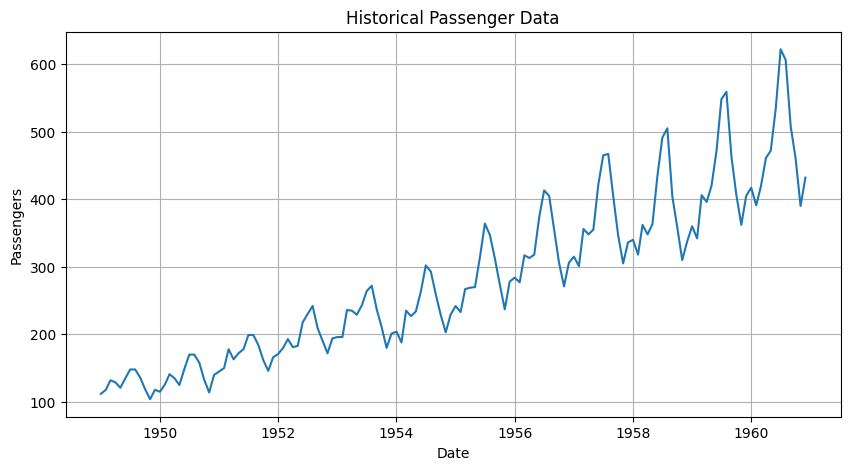

In [4]:
plt.figure(figsize=(10,5))
plt.plot(df['ds'], df['y'])
plt.title("Historical Passenger Data")
plt.xlabel("Date")
plt.ylabel("Passengers")
plt.grid(True)
plt.show()

In [5]:
model = Prophet()
model.fit(df)

INFO:prophet:Disabling weekly seasonality. Run prophet with weekly_seasonality=True to override this.
INFO:prophet:Disabling daily seasonality. Run prophet with daily_seasonality=True to override this.


In [6]:
future = model.make_future_dataframe(periods=24, freq='M')
forecast = model.predict(future)

/usr/local/lib/python3.13/dist-packages/prophet/forecaster.py:2206: FutureWarning: 'M' is deprecated and will be removed in a future version, please use 'ME' instead.
  dates = pd.date_range(


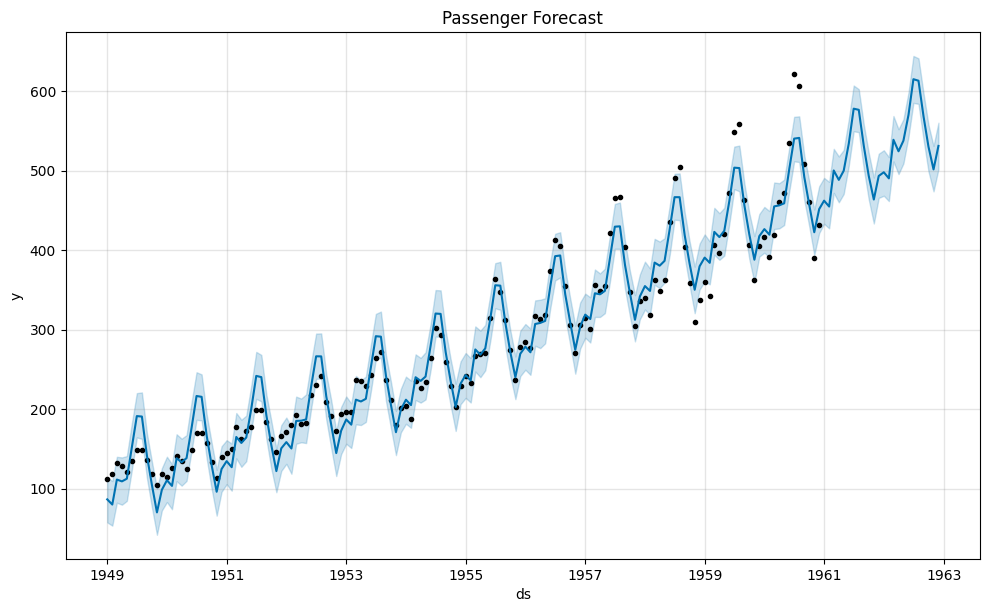

In [7]:
fig = model.plot(forecast)
plt.title("Passenger Forecast")
plt.show()

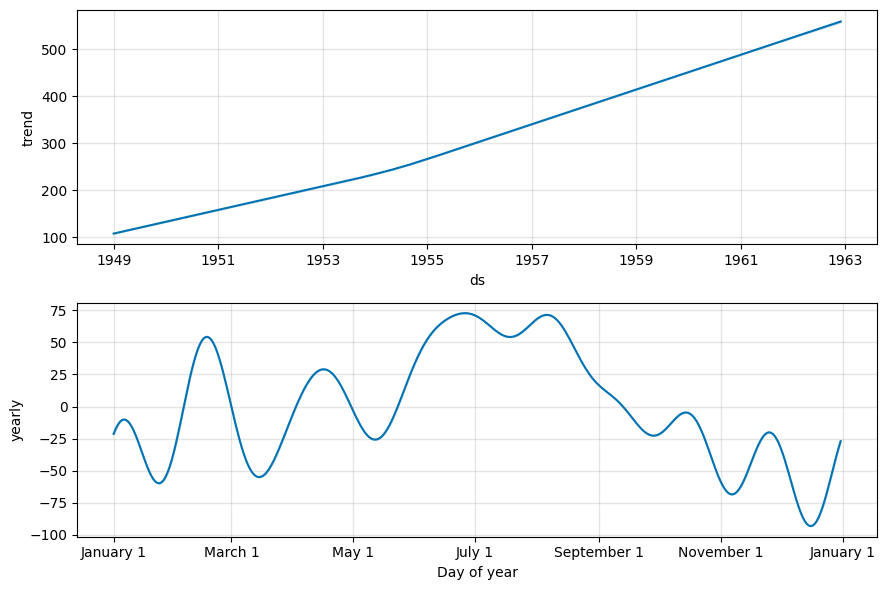

In [8]:
fig2 = model.plot_components(forecast)
plt.show()

In [9]:
forecast[['ds', 'yhat', 'yhat_lower', 'yhat_upper']].tail(24)

,ds,yhat,yhat_lower,yhat_upper
144,1960-12-31,462.142054,433.068656,490.821618
145,1961-01-31,454.750487,427.307325,485.785138
146,1961-02-28,500.127462,471.987854,527.349173
147,1961-03-31,488.301739,460.038153,517.738924
148,1961-04-30,499.823910,470.647584,525.884648
149,1961-05-31,534.006795,506.126500,564.350107
150,1961-06-30,577.839115,549.380850,606.988926
151,1961-07-31,576.391762,548.342180,602.363276
152,1961-08-31,530.603014,501.972253,557.369465
153,1961-09-30,493.296674,463.644218,522.096241
